# Part 5d: the HUD-insured mortgage pathway

The rescue model (Part 5) follows subsidies that end on a **date**. NHPD has a second way for affordability to end: an FHA-insured mortgage with affordability restrictions is **terminated** (prepaid, refinanced, or paid off), recorded as
"Inactive, Terminated Mortgage". This notebook measures how big that pathway is, whether it usually costs affordability, and how much of it the date-based 2026 to 2035 expiry list misses (`src/mortgage_exit.py`).

Two data facts shape the method. NHPD's dictionary says the end date of an insured record is the **scheduled maturity**, and the loan appears in HUD's terminated-mortgage database when it ends. So an early termination shows up as an inactive record whose end date is still
in the future, and the actual termination year is not recorded. A time-split model like Part 5's is therefore not possible; the exposure is estimated from how earlier **cohorts** of loans behaved. And NHPD includes only insured sections that carry affordability restrictions
(Section 236 and its refinances, 221(d)(3) BMIR, and similar), so a terminated loan can mean a lost restriction.

In [1]:
import sys
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import mortgage_exit as M
from viz import apply_style, SERIES, save_figure, SURFACE, MUTED, BASELINE, INK_2, dot, tile_map, SEQUENTIAL

apply_style()
pd.set_option("display.width", 220)
d, p = M.load()
panel = pd.read_csv("data/processed/panel.csv", dtype={"state_fips": str})
abbr = panel.groupby("state_fips").state_abbr.first()

## 1. How big is the pathway, and who is in it?

In [2]:
t = M.pathway_table(d)
display(t[["End Date Passed", "Missing from Subsequent Updates", "Non-programmatic", "Terminated Mortgage", "total_inactive", "terminated_mortgage_share"]].round(3))
ins = d[d.program == "HUD Insured"]
print(f"HUD Insured records: {len(ins)}, of which inactive {int((ins.status == 'Inactive').sum())} ({(ins.status == 'Inactive').mean():.0%}) and active {int((ins.status == 'Active').sum())}")
tm = ins[ins.inactive_reason == "Terminated Mortgage"]
print(f"terminated mortgages: {len(tm)} records; {tm.end_year.gt(2025).mean():.0%} have a scheduled end after 2025 (so they ended early); median scheduled end {tm.end_year.median():.0f}; "
      f"{tm.property_id.nunique()} properties; {len(tm) / t.total_inactive.sum():.0%} of all inactive subsidies")

inactive_reason,End Date Passed,Missing from Subsequent Updates,Non-programmatic,Terminated Mortgage,total_inactive,terminated_mortgage_share
program,,,,,,
HOME,33901,207,0,0,34109,0.00
LIHTC,1754,10459,11358,0,23588,0.00
HUD Insured,724,20,0,14251,14997,0.95
RHS 515,92,6529,0,0,6622,0.00
Public Housing,0,2438,0,0,2438,0.00
Section 202,30,1690,0,0,1720,0.00
Section 8,1400,0,0,0,1407,0.00
State Subsidy,427,0,0,0,428,0.00
RHS 538,0,296,0,0,296,0.00


HUD Insured records: 24799, of which inactive 16847 (68%) and active 7514
terminated mortgages: 14672 records; 48% have a scheduled end after 2025 (so they ended early); median scheduled end 2024; 10536 properties; 17% of all inactive subsidies


## 2. Does termination cost affordability?

Not usually. Most properties whose insured mortgage ended carry other subsidies. The ones that matter are those where the insured loan was the only thing keeping the property assisted.

In [3]:
out = M.outcome_table(d)
rows = {
    "other subsidy ever present": out[out.other_subsidy_ever],
    "other subsidies present but none active now": out[out.other_subsidy_ever & ~out.other_active_now],
    "insured loan was the property's only subsidy ever": out[~out.other_subsidy_ever],
}
cmp = pd.DataFrame({k: {"properties": len(v), "still hold an active subsidy": v.any_active_now.mean(), "active insured record now (refinanced)": v.insured_active_now.mean()} for k, v in rows.items()}).T
display(cmp.round(3))
resc, n_resc = M.rescue_rate(out)
print(f"{len(out)} properties lost an insured mortgage; {out.other_active_now.mean():.0%} have another active subsidy today. For the {n_resc} with no other active subsidy, {resc:.1%} have a new active insured record (refinanced)")

,properties,still hold an active subsidy,active insured record now (refinanced)
other subsidy ever present,9025.0,0.896,0.308
other subsidies present but none active now,1068.0,0.125,0.125
insured loan was the property's only subsidy ever,1511.0,0.039,0.039


10536 properties lost an insured mortgage; 76% have another active subsidy today. For the 2579 with no other active subsidy, 7.4% have a new active insured record (refinanced)


## 3. How quickly do insured loans end?

Share of insured subsidy records that have terminated, by the year the record started (3-year smoothed). Recent cohorts terminate fast: about half or more of the records started in 2010 to 2012 are already gone, and 57 to 75 percent of those started in 2005 to 2008.

start_year,1975,1985,1995,2000,2005,2008,2010,2012,2015,2018,2020,2023
share_terminated,0.82,0.46,0.95,0.86,0.75,0.57,0.61,0.51,0.38,0.24,0.06,0.01
subsidies,450.00,115.00,396.00,202.00,590.00,383.00,376.00,730.00,541.00,496.00,515.00,305.00


C:\Users\erick\AppData\Local\Temp\ipykernel_44280\3292891580.py:10: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


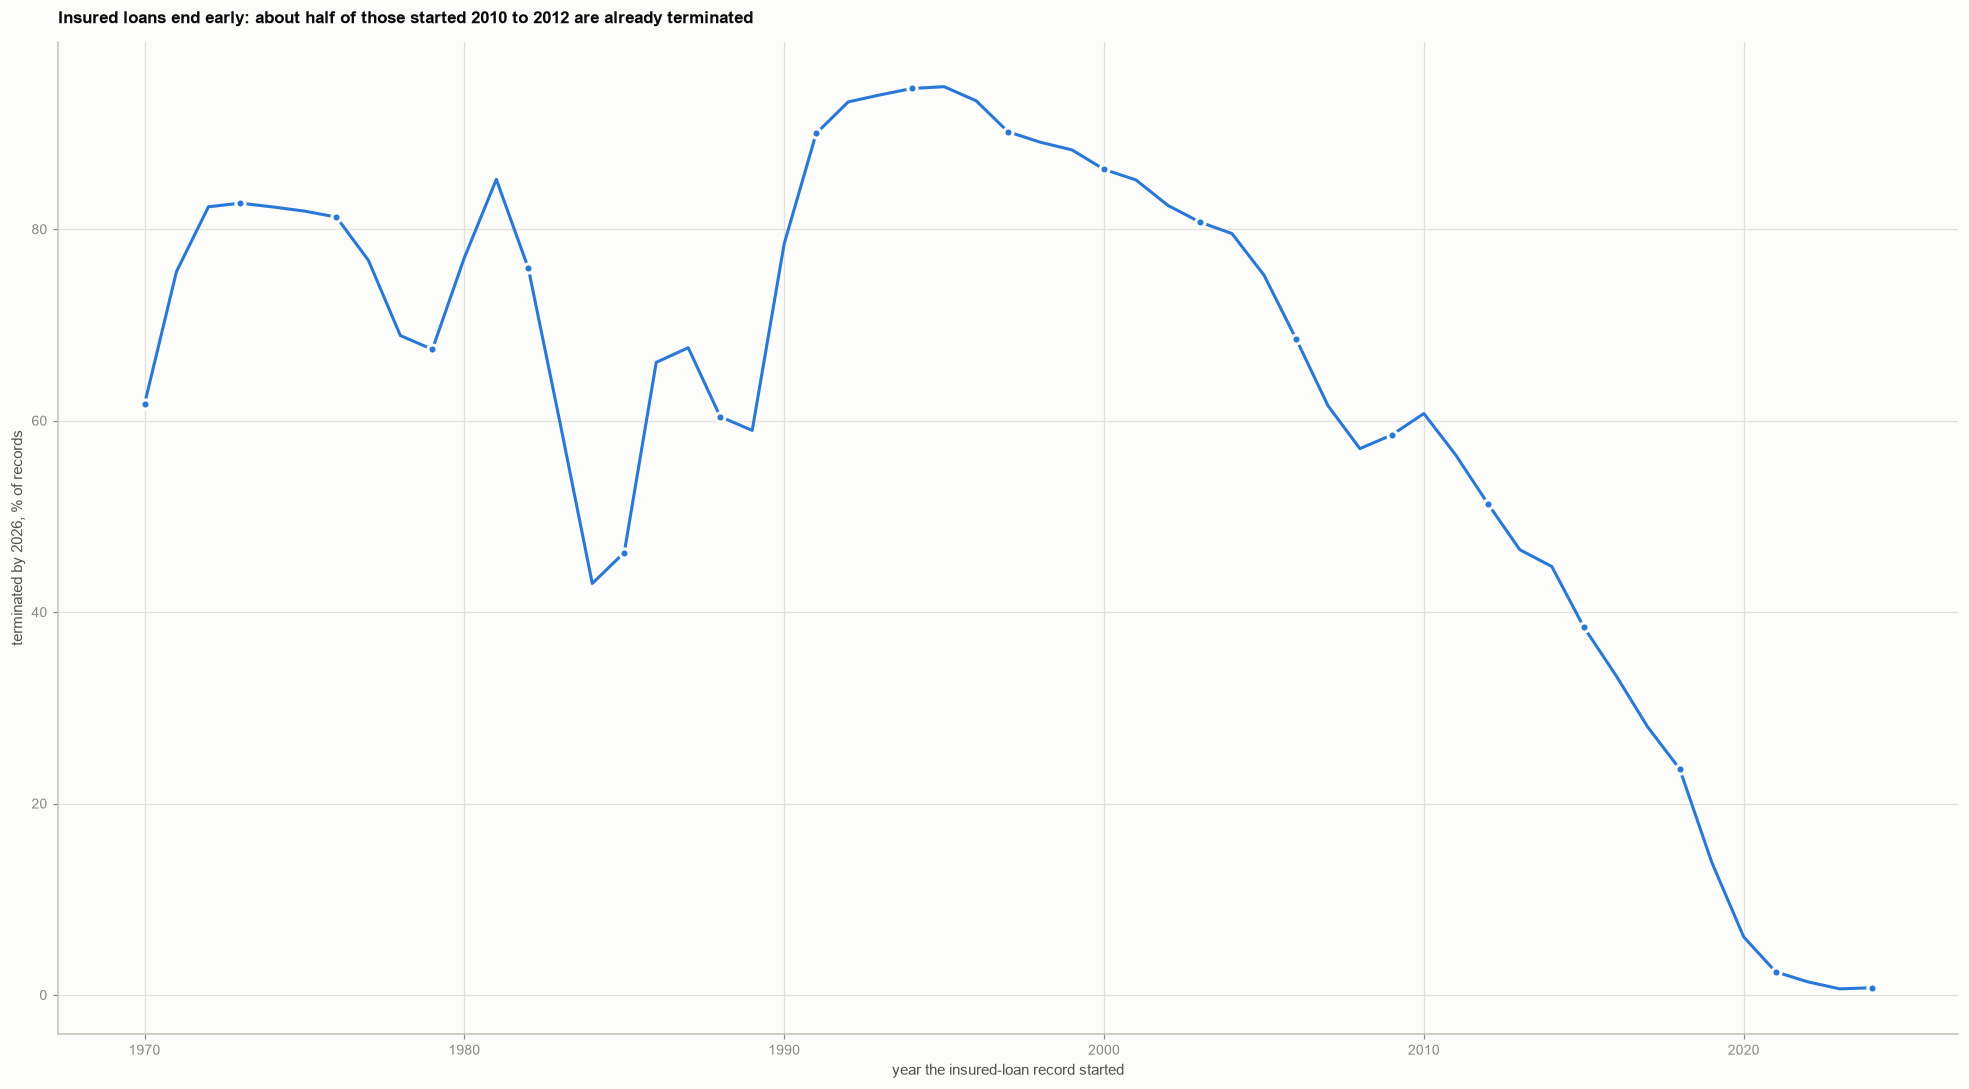

In [4]:
curve = M.cohort_curve(d)
display(curve.loc[[1975, 1985, 1995, 2000, 2005, 2008, 2010, 2012, 2015, 2018, 2020, 2023]].round(2).T)
fig, ax = plt.subplots(figsize=(18, 10))
cc = curve.loc[1970:2024]
ax.plot(cc.index, 100 * cc.share_terminated, color=SERIES[0])
for x, v in zip(cc.index[::3], cc.share_terminated[::3]):
    dot(ax, x, 100 * v, SERIES[0])
ax.set_xlabel("year the insured-loan record started"); ax.set_ylabel("terminated by 2026, % of records")
ax.set_title("Insured loans end early: about half of those started 2010 to 2012 are already terminated", fontsize=11, loc="left")
fig.tight_layout()
save_figure(fig, "54_cohort_curve", part="05_preservation")
plt.show()

## 4. What the date-based expiry list misses

The 2026 to 2035 list counts properties by **scheduled** end date, and insured loans rarely end on schedule. The exposure is the set of properties whose **only active subsidy** is an insured loan and whose scheduled end is not already on the list. For each, the share expected to terminate
by 2035 is read from the loans that started nine years earlier (the cohort that is nine years older today); net loss multiplies by one minus the historical refinance rate. The low case uses seven years and the 7.4 percent refinance rate, the central case nine years and 7.4 percent, the high case
eleven years and the 3.9 percent rate of properties that never had another subsidy.

In [5]:
exp, info = M.exposure_by_state(d, p)
exp.index.name = "state_fips"
exp["state"] = exp.index.map(abbr)
exp.to_csv("outputs/tables/mortgage_exit_state.csv")
tot = exp[["exposed_properties", "exposed_units", "terminate_low", "terminate_central", "terminate_high", "mortgage_unrescued_low", "mortgage_unrescued_central", "mortgage_unrescued_high"]].sum()
display(tot.round(0).to_frame("national").T)
a = d[d.status == "Active"]
n_ins_active = a[a.program == "HUD Insured"].property_id.nunique()
print(f"active properties with an insured loan: {n_ins_active}; exposed (insured is the only active subsidy, not on the 2026-2035 list): {int(tot.exposed_properties)} properties, {tot.exposed_units:,.0f} units, median start year "
      f"{M.exposed_properties(d, p).start_year.median():.0f}")
print(f"expected terminations by 2035: {tot.terminate_low:,.0f} to {tot.terminate_high:,.0f} units; net unrescued {tot.mortgage_unrescued_low:,.0f} to {tot.mortgage_unrescued_high:,.0f} (central {tot.mortgage_unrescued_central:,.0f})")
display(exp.sort_values("mortgage_unrescued_central", ascending=False).head(8)[["state", "exposed_properties", "exposed_units", "mortgage_unrescued_low", "mortgage_unrescued_central", "mortgage_unrescued_high"]].round(0).reset_index(drop=True))

,exposed_properties,exposed_units,terminate_low,terminate_central,terminate_high,mortgage_unrescued_low,mortgage_unrescued_central,mortgage_unrescued_high
national,558.0,78195.0,30047.0,37639.0,43895.0,27810.0,34837.0,42181.0


active properties with an insured loan: 7305; exposed (insured is the only active subsidy, not on the 2026-2035 list): 558 properties, 78,195 units, median start year 2019
expected terminations by 2035: 30,047 to 43,895 units; net unrescued 27,810 to 42,181 (central 34,837)


,state,exposed_properties,exposed_units,mortgage_unrescued_low,mortgage_unrescued_central,mortgage_unrescued_high
0,MA,97,11715.0,4313.0,5250.0,6458.0
1,NY,26,12068.0,3767.0,4845.0,5762.0
2,TX,43,7438.0,2634.0,3169.0,3952.0
3,IL,42,5375.0,1985.0,2514.0,3000.0
4,MD,35,5625.0,1835.0,2293.0,2782.0
5,CA,27,3562.0,1265.0,1633.0,1960.0
6,IN,26,3243.0,1280.0,1621.0,1963.0
7,MN,39,2760.0,1065.0,1372.0,1650.0


C:\Users\erick\AppData\Local\Temp\ipykernel_44280\1690334365.py:10: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


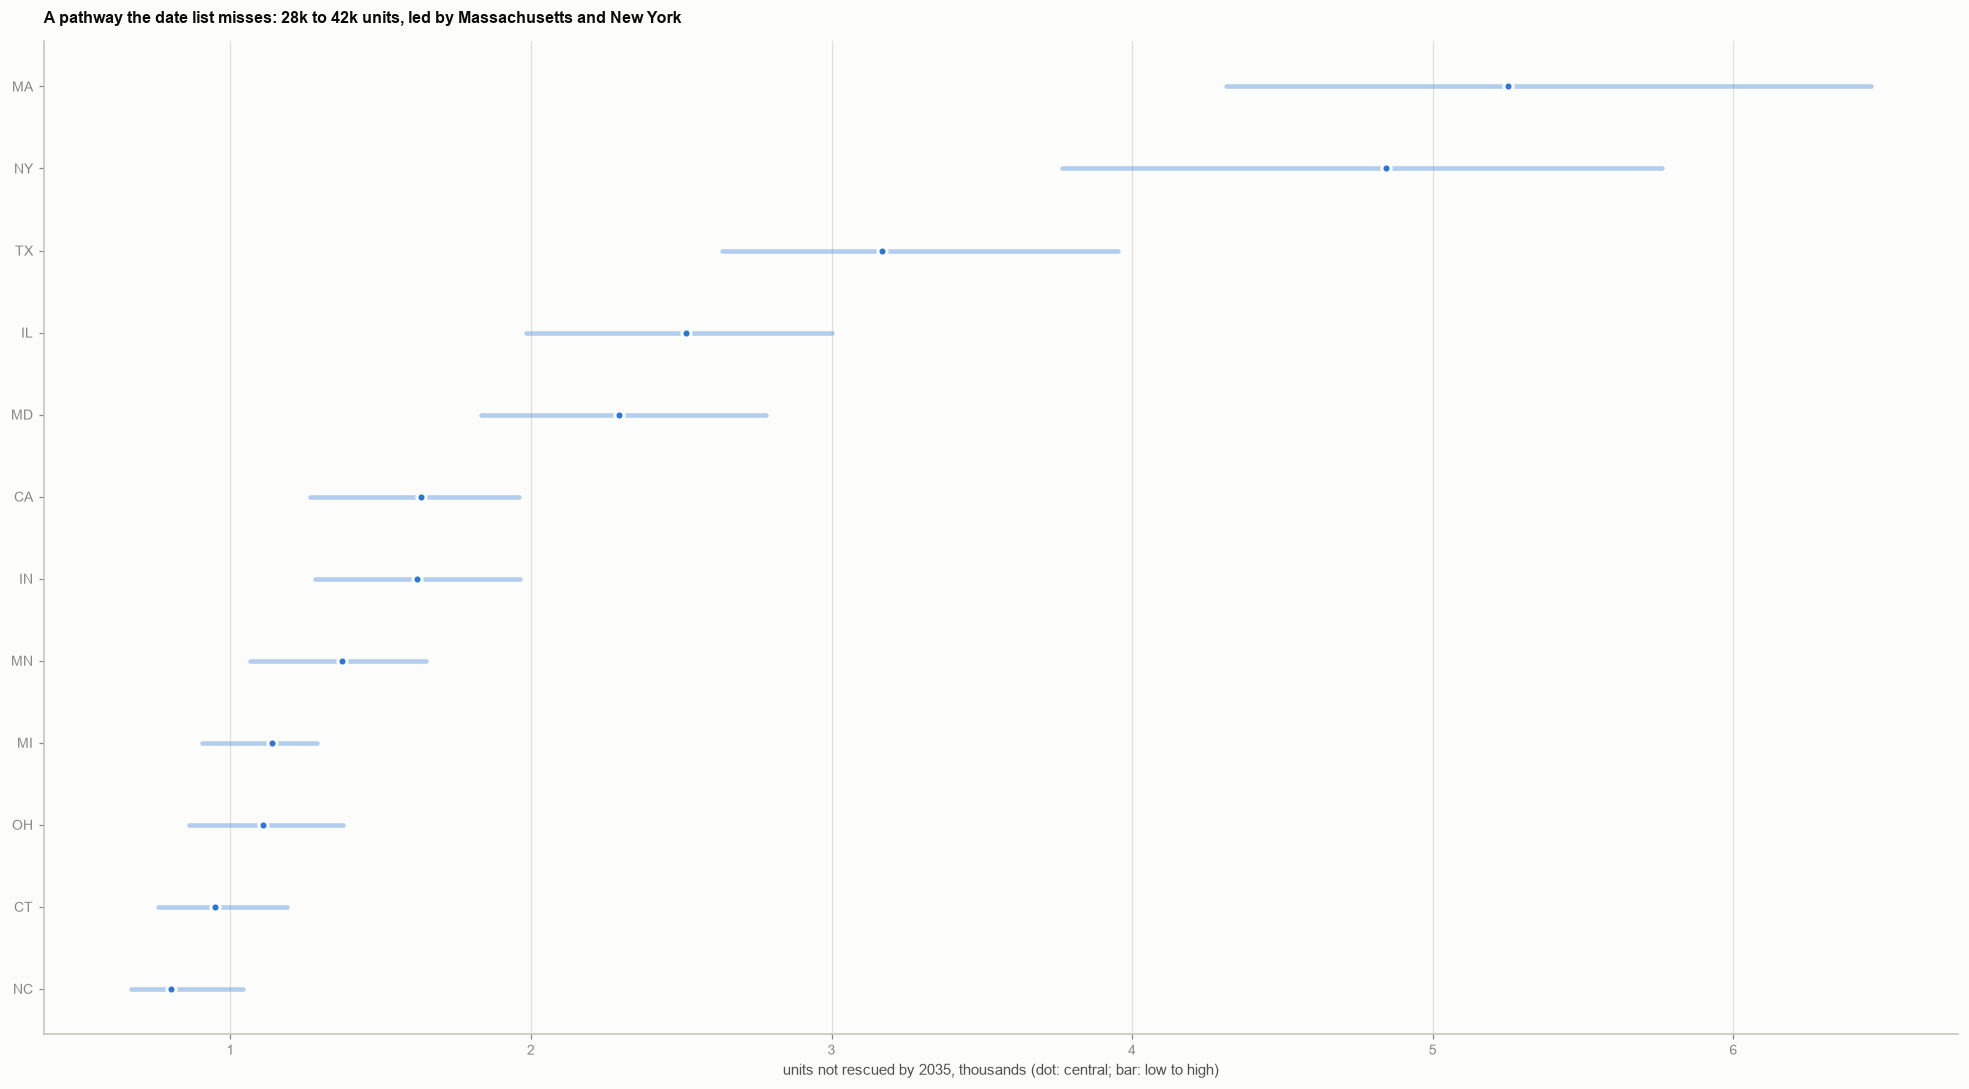

In [6]:
top = exp.sort_values("mortgage_unrescued_central", ascending=False).head(12)[::-1]
fig, ax = plt.subplots(figsize=(18, 10))
ys = np.arange(len(top))
for yi, (_, r) in zip(ys, top.iterrows()):
    ax.plot([r.mortgage_unrescued_low / 1000, r.mortgage_unrescued_high / 1000], [yi, yi], color=SERIES[0], alpha=0.35, lw=3, solid_capstyle="round")
    dot(ax, r.mortgage_unrescued_central / 1000, yi, SERIES[0])
ax.set_yticks(ys, top.state, fontsize=9); ax.grid(axis="y", visible=False)
ax.set_xlabel("units not rescued by 2035, thousands (dot: central; bar: low to high)")
ax.set_title(f"A pathway the date list misses: {tot.mortgage_unrescued_low / 1000:.0f}k to {tot.mortgage_unrescued_high / 1000:.0f}k units, led by Massachusetts and New York", fontsize=10.5, loc="left")
fig.tight_layout()
save_figure(fig, "54_mortgage_exposure_states", part="05_preservation")
plt.show()

## Findings

**The pathway is large but mostly harmless to affordability.** HUD-insured mortgages with affordability restrictions are 24,799 NHPD records, 68 percent of them already inactive. "Terminated Mortgage" accounts for 14,672 records (17 percent of all inactive subsidies in NHPD, 95 percent of inactive HUD Insured
records, and none for any other program). 48 percent of those records have a scheduled end after 2025, so the loans ended early (prepayment or refinance); the actual termination year is not recorded.

**Termination usually does not end affordability.** 10,536 properties lost an insured mortgage. 86 percent (9,025) also had other subsidies, and 90 percent of those still hold an active subsidy; 76 percent of all of them have another active subsidy today. It does end it when the insured loan was
the only thing: of the 1,511 properties where it was their only subsidy ever, 3.9 percent are assisted now; of the 2,579 with no other active subsidy, 7.4 percent have a new active insured record (a refinance). So a terminated mortgage matters for the property only where nothing else keeps it assisted.

**Insured loans end quickly.** Of records started in 2005, 75 percent have terminated (57 percent for 2008, 61 for 2010, 51 for 2012, 38 for 2015, 24 for 2018), a pattern of repeated refinancing as well as exit.

**What the date-based list misses.** 7,305 active properties carry an insured loan. In 558 of them (78,195 units, median start year 2019) it is the only active subsidy and the scheduled end is after 2035 or missing, so they are not on the 2026 to 2035 list (27 other insured-only properties, 4,250 units, are, and are
already in Part 5). If these loans follow the earlier cohorts, 30,000 to 44,000 of those units see the mortgage end by 2035, and **27,800 to 42,200 units (central 34,800) would not be rescued**. The largest exposures are Massachusetts (4,300 to 6,500 units, 97 properties), New York (3,800 to 5,800), Texas (2,600 to 4,000),
Illinois (2,000 to 3,000), Maryland (1,800 to 2,800), California, Indiana, and Minnesota.

**What it means.** For the combined answer this adds a fourth piece of about 3 to 4 percent on top of the others, concentrated in a few states; it is not what drives the total. Its use is to correct the date-based list, which treats an insured loan as lasting to its scheduled maturity, and to name where the exposure sits (Massachusetts, New York, Texas, Illinois, Maryland).

**Caveats.** Termination dates are not recorded, so the exposure rests on an assumption that recent loans will follow the pace of older ones, and recent cohorts contain refinance cycles; only the low, central, and high cases (seven, nine, and eleven years of cohort shift, 7.4 and 3.9 percent refinance rates) express that uncertainty. NHPD does not
say how long each restriction runs after termination, and "assisted units" on insured records can overlap other subsidies. The 7.4 percent refinance rate comes from past terminations. Tables: `outputs/tables/mortgage_exit_state.csv`.